# Implementation and Evaluation of a NetFlow Behavioral Anomaly Detection Prototype

**CSC 786: Computer Science Problems**

**Student:** Carlos Ocasio  
**Professor:** Dr. Abid Mehmood  
**Experiment:** Seven Day Synthetic NetFlow Experiment

## Project Overview

This notebook documents the implementation and evaluation of a NetFlow behavioral anomaly detection prototype using Isolation Forest.

The experiment uses programmatically generated synthetic NetFlow records representing seven days of network traffic. Traffic records are processed into 1, 5, and 10 minute aggregation windows, and 12 traffic features are extracted for anomaly detection.

The objective is to evaluate how temporal aggregation affects Isolation Forest performance and examine the tradeoffs associated with different anomaly detection thresholds.

Model performance is evaluated using precision, recall, F1 score, false positive rate, and ROC AUC.

The notebook is intended to support reproducibility by allowing others to execute the analysis using the provided datasets and Python scripts.

In [1]:
!git clone https://github.com/carlosocasio/csc786-netflow-anomaly-detection.git

fatal: destination path 'csc786-netflow-anomaly-detection' already exists and is not an empty directory.


In [2]:
from pathlib import Path

BASE = Path("/content/csc786-netflow-anomaly-detection")
DATA = BASE / "data" / "synthetic_7d"
RESULTS = BASE / "results" / "synthetic_7d"

print("Repository exists:", BASE.exists())
print("Data directory exists:", DATA.exists())

Repository exists: True
Data directory exists: True


In [3]:
import pandas as pd

print("Raw NetFlow:", (DATA / "netflow_7d_raw.csv").exists())
print("Experiment log:", list(DATA.glob("experiment_*.csv")))

for minutes in [1, 5, 10]:
    file = DATA / f"netflow_features_{minutes}min.csv"
    df = pd.read_csv(file)

    print(f"{minutes} minute windows: {len(df)}")

Raw NetFlow: True
Experiment log: [PosixPath('/content/csc786-netflow-anomaly-detection/data/synthetic_7d/experiment_7d.csv')]
1 minute windows: 10080
5 minute windows: 2016
10 minute windows: 1008


In [11]:
!python /content/csc786-netflow-anomaly-detection/scripts/synthetic/feature_engineering_synthetic.py

Loaded 95318 synthetic NetFlow records
Loaded 56 anomaly episodes
Experiment start: 2026-11-16 00:00:00+00:00
Experiment end: 2026-11-23 00:00:00+00:00
1 minute windows: 10080 records, 162 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/synthetic_7d/netflow_features_1min.csv
5 minute windows: 2016 records, 74 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/synthetic_7d/netflow_features_5min.csv
10 minute windows: 1008 records, 64 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/synthetic_7d/netflow_features_10min.csv


In [4]:
!python /content/csc786-netflow-anomaly-detection/scripts/synthetic/isolation_forest_baseline_synthetic.py


Isolation Forest: 1 minute aggregation
Training windows: 7050
Normal training windows used: 6939
Testing windows: 3030
True anomalies: 51
Predicted anomalies: 472

Threshold: 0.5251
Precision: 0.106
Recall: 0.980
F1 score: 0.191
False positive rate: 0.142
ROC AUC: 0.977

Confusion Matrix
True negatives: 2557
False positives: 422
False negatives: 1
True positives: 50

Saved predictions: /content/csc786-netflow-anomaly-detection/results/synthetic_7d/predictions_1min.csv

Isolation Forest: 5 minute aggregation
Training windows: 1410
Normal training windows used: 1358
Testing windows: 606
True anomalies: 22
Predicted anomalies: 182

Threshold: 0.5150
Precision: 0.110
Recall: 0.909
F1 score: 0.196
False positive rate: 0.277
ROC AUC: 0.960

Confusion Matrix
True negatives: 422
False positives: 162
False negatives: 2
True positives: 20

Saved predictions: /content/csc786-netflow-anomaly-detection/results/synthetic_7d/predictions_5min.csv

Isolation Forest: 10 minute aggregation
Training wind

In [5]:
baseline_results = pd.read_csv(RESULTS / "isolation_forest_comparison.csv")

baseline_results.round(3)

,aggregation_minutes,training_windows,normal_training_windows,testing_windows,true_anomalies,predicted_anomalies,threshold,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,7050,6939,3030,51,472,0.525,0.106,0.980,0.191,0.142,0.977,2557,422,1,50
1,5,1410,1358,606,22,182,0.515,0.110,0.909,0.196,0.277,0.960,422,162,2,20
2,10,705,660,303,19,127,0.507,0.134,0.895,0.233,0.387,0.944,174,110,2,17


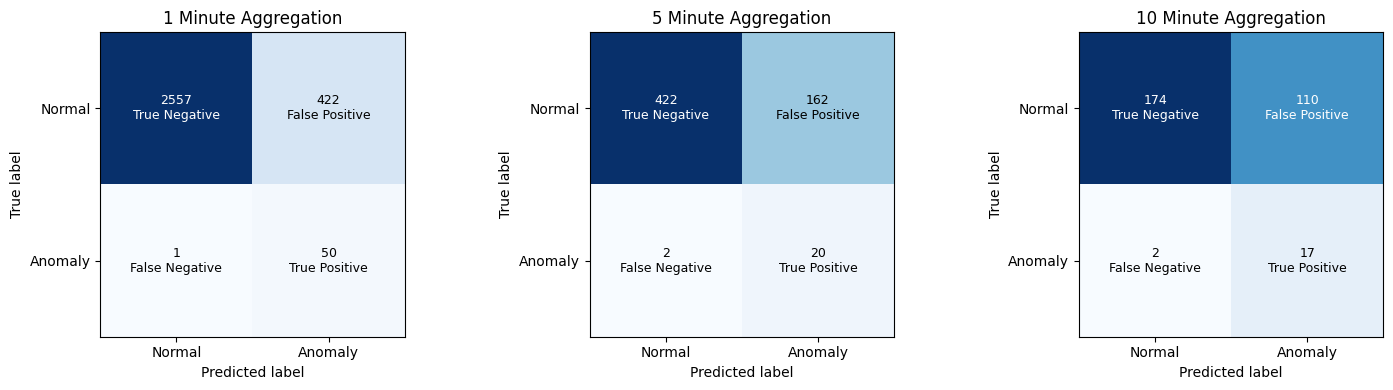

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cell_labels = [
    ["True Negative", "False Positive"],
    ["False Negative", "True Positive"]
]

for ax, minutes in zip(axes, [1, 5, 10]):
    predictions = pd.read_csv(RESULTS / f"predictions_{minutes}min.csv")

    matrix = confusion_matrix(
        predictions["label"],
        predictions["prediction"],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Normal", "Anomaly"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        include_values=False
    )

    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            label = cell_labels[row][col]

            color = "white" if value > matrix.max() / 2 else "black"

            ax.text(
                col, row,
                f"{value}\n{label}",
                ha="center",
                va="center",
                fontsize=9,
                color=color
            )

    ax.set_title(f"{minutes} Minute Aggregation")

plt.tight_layout()
plt.show()

In [7]:
!python /content/csc786-netflow-anomaly-detection/scripts/synthetic/isolation_forest_threshold_synthetic.py


1 minute aggregation
Normal training windows: 6939
Testing windows: 3030
True anomalous windows: 51
Percentile 95: Threshold=0.5585 Alerts=289 Precision=0.163 Recall=0.922 F1=0.276 FPR=0.081
Percentile 90: Threshold=0.5251 Alerts=472 Precision=0.106 Recall=0.980 F1=0.191 FPR=0.142
Percentile 85: Threshold=0.5026 Alerts=668 Precision=0.075 Recall=0.980 F1=0.139 FPR=0.207
Percentile 80: Threshold=0.4893 Alerts=827 Precision=0.060 Recall=0.980 F1=0.114 FPR=0.261
Saved scores: /content/csc786-netflow-anomaly-detection/results/synthetic_7d/threshold_scores_1min.csv

5 minute aggregation
Normal training windows: 1358
Testing windows: 606
True anomalous windows: 22
Percentile 95: Threshold=0.5402 Alerts=139 Precision=0.144 Recall=0.909 F1=0.248 FPR=0.204
Percentile 90: Threshold=0.5150 Alerts=182 Precision=0.110 Recall=0.909 F1=0.196 FPR=0.277
Percentile 85: Threshold=0.4970 Alerts=218 Precision=0.092 Recall=0.909 F1=0.167 FPR=0.339
Percentile 80: Threshold=0.4854 Alerts=247 Precision=0.085 

In [8]:
threshold_results = pd.read_csv(RESULTS / "threshold_comparison.csv")

threshold_results.round(3)

,aggregation_minutes,percentile,threshold,training_windows,testing_windows,true_anomalies,alert_count,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,95,0.558,6939,3030,51,289,0.163,0.922,0.276,0.081,0.977,2737,242,4,47
1,1,90,0.525,6939,3030,51,472,0.106,0.980,0.191,0.142,0.977,2557,422,1,50
2,1,85,0.503,6939,3030,51,668,0.075,0.980,0.139,0.207,0.977,2361,618,1,50
3,1,80,0.489,6939,3030,51,827,0.060,0.980,0.114,0.261,0.977,2202,777,1,50
4,5,95,0.540,1358,606,22,139,0.144,0.909,0.248,0.204,0.960,465,119,2,20
5,5,90,0.515,1358,606,22,182,0.110,0.909,0.196,0.277,0.960,422,162,2,20
6,5,85,0.497,1358,606,22,218,0.092,0.909,0.167,0.339,0.960,386,198,2,20
7,5,80,0.485,1358,606,22,247,0.085,0.955,0.156,0.387,0.960,358,226,1,21
8,10,95,0.536,660,303,19,92,0.185,0.895,0.306,0.264,0.944,209,75,2,17
9,10,90,0.507,660,303,19,127,0.134,0.895,0.233,0.387,0.944,174,110,2,17


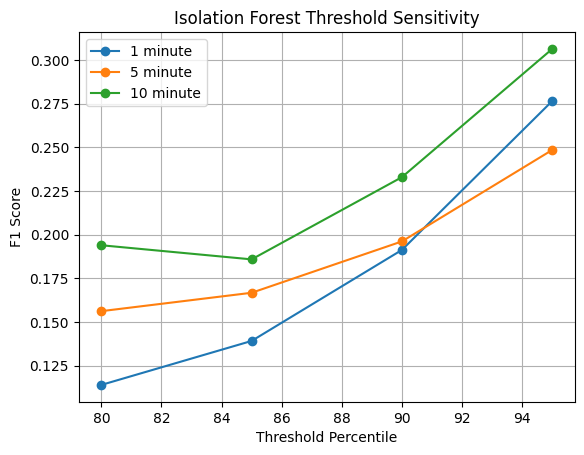

In [9]:
import matplotlib.pyplot as plt

for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["f1_score"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("F1 Score")
plt.title("Isolation Forest Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

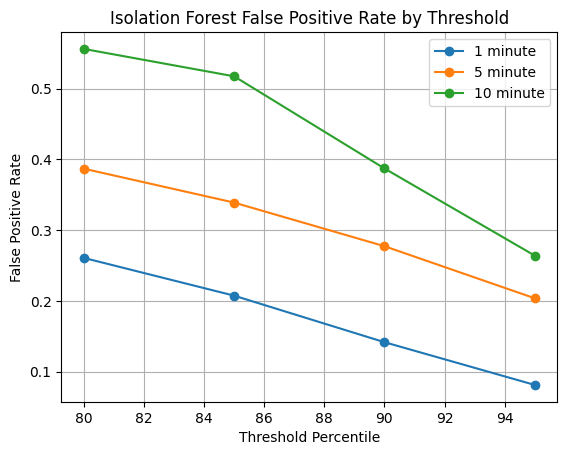

In [10]:
for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["false_positive_rate"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("False Positive Rate")
plt.title("Isolation Forest False Positive Rate by Threshold")
plt.legend()
plt.grid(True)
plt.show()

**Results and Discussion**

The seven day synthetic experiment evaluated Isolation Forest using NetFlow features aggregated into 1, 5, and 10 minute intervals.

At the baseline 90th percentile threshold, the 10 minute aggregation achieved the highest F1 score of 0.233, compared with 0.191 for the 1 minute interval and 0.196 for the 5 minute interval. However, the 10 minute interval also produced the highest false positive rate of 0.387, compared with 0.142 for the 1 minute interval and 0.277 for the 5 minute interval.

The 1 minute aggregation achieved the highest recall of 0.980 and ROC AUC of 0.977, indicating stronger anomaly detection performance in these metrics. However, precision remained low at 0.106, with 422 false positives among 472 generated alerts.

The threshold sensitivity evaluation showed that increasing the threshold percentile reduced the number of alerts and false positives across all three aggregation intervals. For the 1 minute interval, increasing the threshold from the 80th to the 95th percentile reduced the false positive rate from 0.261 to 0.081, while recall decreased from 0.980 to 0.922.

The 95th percentile produced the highest F1 score across all three aggregation intervals, achieving 0.276 for the 1 minute interval, 0.248 for the 5 minute interval, and 0.306 for the 10 minute interval.

These findings demonstrate that temporal aggregation and threshold selection influence anomaly detection performance. Although longer aggregation intervals achieved higher F1 scores in this experiment, they also produced higher false positive rates. Threshold selection therefore represents an important tradeoff between detecting anomalous traffic and limiting unnecessary alerts.

**Limitations**

The experiment used programmatically generated synthetic NetFlow records rather than traffic collected from a production network. Although the dataset represented seven days of network activity, its traffic patterns and anomaly characteristics may not fully reflect real network environments.

The number and proportion of anomalous windows also varied across aggregation intervals, which limits direct comparisons of detection performance. Additionally, the relatively low precision across all three intervals indicates that the model generated substantial numbers of false positives.

Additional experiments using laboratory and production network traffic would help determine whether these findings generalize to other traffic patterns and network environments.